In [ ]:
import sys
from pathlib import Path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from src.data_cleaning import DataCleaning 


In [7]:
cleaner=DataCleaning(pd.read_csv(project_root/"data"/"raw.csv"))
data_cleaned=cleaner.run()
display(cleaner.report_df())
print(data_cleaned.shape)
print(data_cleaned.columns)
data_cleaned.head()

,step,rows_before,rows_after,rows_removed,note
0,start,15411,15411,0,
1,drop_unnamed_columns,15411,15411,0,1 column(s) dropped
2,handle_missing_values,15411,15411,0,0 feature cell(s) imputed
3,drop_duplicate_rows,15411,15244,167,
4,drop_redundant_columns,15244,15244,0,car_name dropped (== brand + model)
5,remove_impossible_values,15244,15242,2,
6,outliers_domain_rule,15242,15237,5,"km/year > 150,000"


(15237, 12)
Index(['brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price'],
      dtype='object')


,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,maruti,alto,9,120000,individual,petrol,manual,19.70,796,46.30,5,120000
1,hyundai,grand,5,20000,individual,petrol,manual,18.90,1197,82.00,5,550000
2,hyundai,i20,11,60000,individual,petrol,manual,17.00,1197,80.00,5,215000
3,maruti,alto,9,37000,individual,petrol,manual,20.92,998,67.10,5,226000
4,ford,ecosport,6,30000,dealer,diesel,manual,22.77,1498,98.59,5,570000


In [8]:
df = data_cleaned.copy()

df["km_per_year"] = df["km_driven"] / df["vehicle_age"].clip(lower=1)

df["power_to_displacement"] = df["max_power"] / df["engine"]

df[["vehicle_age", "km_driven", "km_per_year", "engine", "max_power", "power_to_displacement"]].head()

,vehicle_age,km_driven,km_per_year,engine,max_power,power_to_displacement
0,9,120000,13333.333333,796,46.30,0.058166
1,5,20000,4000.000000,1197,82.00,0.068505
2,11,60000,5454.545455,1197,80.00,0.066834
3,9,37000,4111.111111,998,67.10,0.067234
4,6,30000,5000.000000,1498,98.59,0.065814


In [9]:
new_cols = ["km_per_year", "power_to_displacement"]
print("NaN values     :", df[new_cols].isnull().sum().to_dict())
print("Infinite values:", np.isinf(df[new_cols]).sum().to_dict())
print("Negative values:", (df[new_cols] < 0).sum().to_dict())
print("Cars with vehicle_age = 0:", (df["vehicle_age"] == 0).sum(), "(clip(lower=1) keeps km_per_year safe)")
display(df[new_cols].describe().round(3).T)

NaN values     : {'km_per_year': 0, 'power_to_displacement': 0}
Infinite values: {'km_per_year': 0, 'power_to_displacement': 0}
Negative values: {'km_per_year': 0, 'power_to_displacement': 0}
Cars with vehicle_age = 0: 4 (clip(lower=1) keeps km_per_year safe)


,count,mean,std,min,25%,50%,75%,max
km_per_year,15237.0,9757.282,6620.813,100.000,5833.333,8428.571,12166.667,150000.000
power_to_displacement,15237.0,0.068,0.012,0.025,0.062,0.067,0.072,0.156


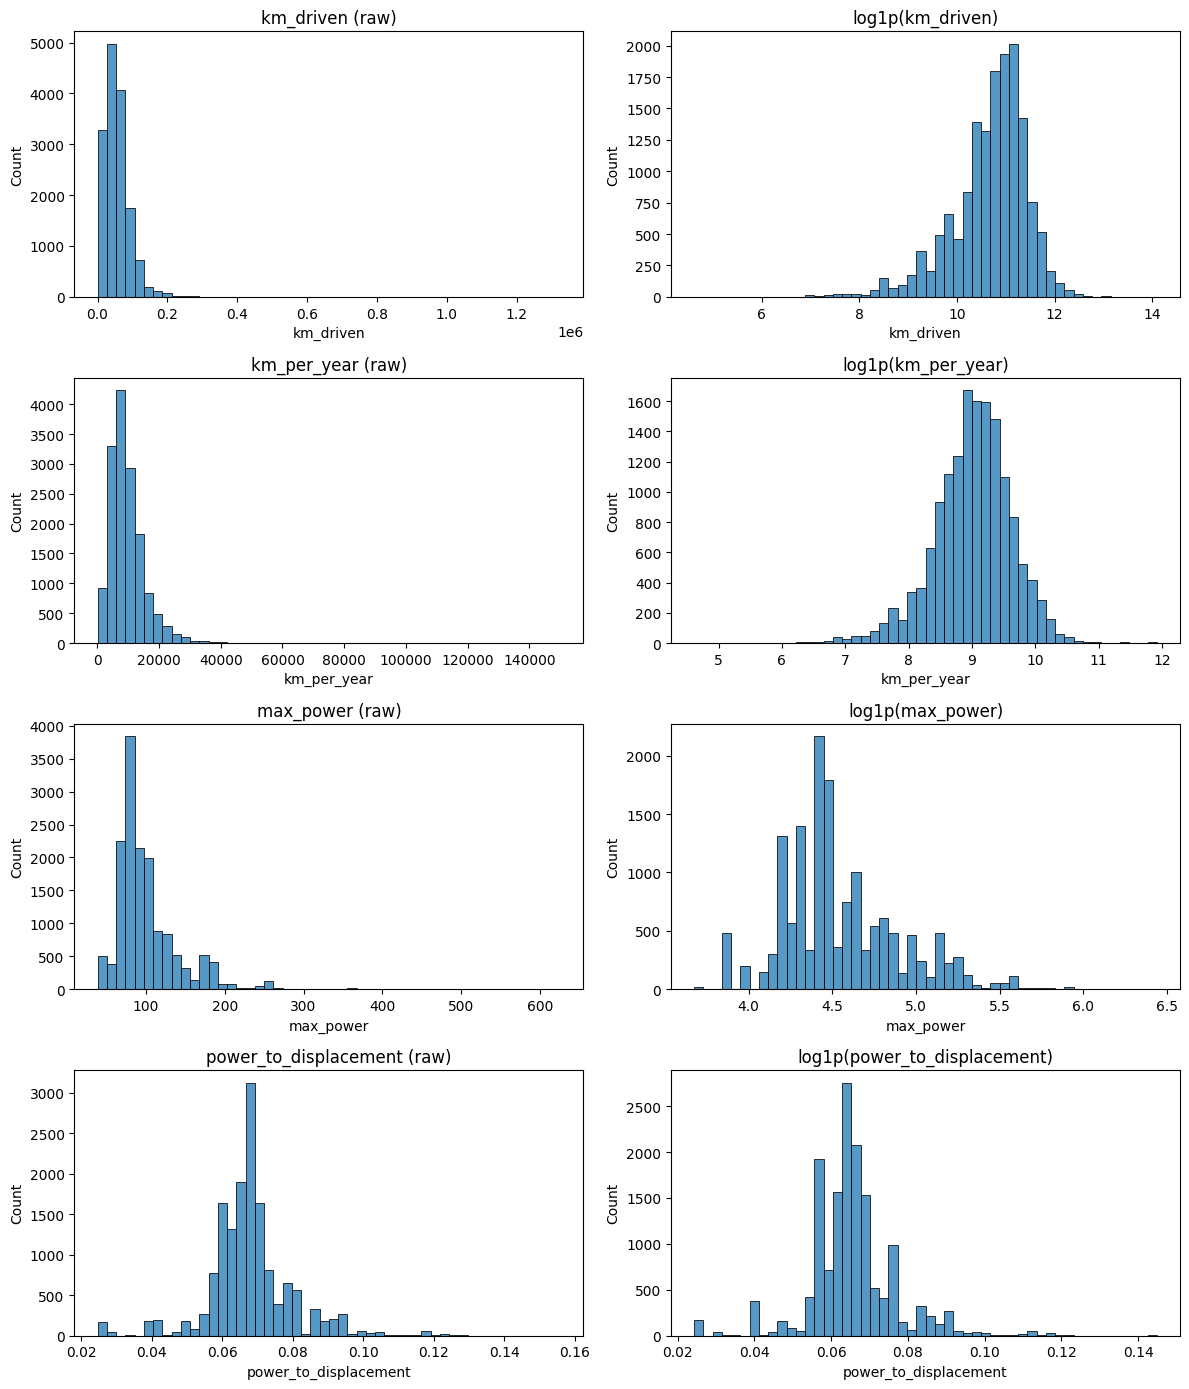

,skew raw,skew log1p
km_driven,5.49,-1.07
km_per_year,5.27,-0.53
max_power,2.49,0.77
power_to_displacement,0.32,0.22


In [10]:
cols = ["km_driven", "km_per_year", "max_power", "power_to_displacement"]
fig, axes = plt.subplots(len(cols), 2, figsize=(12, 3.5 * len(cols)))
for i, c in enumerate(cols):
    sns.histplot(df[c], bins=50, ax=axes[i, 0])
    axes[i, 0].set_title(f"{c} (raw)")
    sns.histplot(np.log1p(df[c]), bins=50, ax=axes[i, 1])
    axes[i, 1].set_title(f"log1p({c})")
plt.tight_layout()
plt.show()

skew = pd.DataFrame({"skew raw": df[cols].skew(), "skew log1p": np.log1p(df[cols]).skew()})
skew.round(2)

In [11]:
df["log_price"] = np.log1p(df["selling_price"])
test_cols = ["vehicle_age", "km_driven", "km_per_year", "engine", "max_power", "power_to_displacement", "mileage", "seats"]
corr = df[test_cols + ["log_price"]].corr(method="spearman")["log_price"].drop("log_price")
corr.sort_values(key=abs, ascending=False).round(2).to_frame("corr with log_price")

,corr with log_price
max_power,0.72
engine,0.64
vehicle_age,-0.48
power_to_displacement,0.37
mileage,-0.28
seats,0.27
km_per_year,0.22
km_driven,-0.17


In [12]:
# how the new features correlate with the old ones (a feature that copies an old one adds little)
df[["km_driven", "vehicle_age", "km_per_year", "engine", "max_power", "power_to_displacement"]].corr(method="spearman").round(2)

,km_driven,vehicle_age,km_per_year,engine,max_power,power_to_displacement
km_driven,1.00,0.58,0.65,0.27,0.10,-0.26
vehicle_age,0.58,1.00,-0.17,0.09,-0.03,-0.20
km_per_year,0.65,-0.17,1.00,0.25,0.14,-0.14
engine,0.27,0.09,0.25,1.00,0.83,0.09
max_power,0.10,-0.03,0.14,0.83,1.00,0.52
power_to_displacement,-0.26,-0.20,-0.14,0.09,0.52,1.00


In [ ]:
# split first, so the experiments never see the test data
X = df.drop(columns=["selling_price", "log_price"])
y = df["selling_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# a small pipeline for the experiments 
onehot_cols = ["seller_type", "fuel_type", "transmission_type"]
target_enc_cols = ["brand", "model"]

def make_pipeline(model, scale=False, number_cols=None):
    number_step = StandardScaler() if scale else "passthrough"
    prep = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
        ("target_enc", TargetEncoder(target_type="continuous", random_state=42), target_enc_cols),
        ("numbers", number_step, number_cols),
    ])
    pipe = Pipeline([("prep", prep), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)


folds = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"r2": "r2", "mape": "neg_mean_absolute_percentage_error"}

base = ["vehicle_age", "km_driven", "mileage", "engine", "max_power", "seats"]

experiments = {
    "1. baseline (original columns)":              base,
    "2. + km_per_year":                            base + ["km_per_year"],
    "3. + power_to_displacement":                  base + ["power_to_displacement"],
    "4. + both new features":                      base + ["km_per_year", "power_to_displacement"],
    "5. both new, but REMOVE km_driven":           [c for c in base if c != "km_driven"] + ["km_per_year", "power_to_displacement"],
    "6. both new, but REMOVE vehicle_age":         [c for c in base if c != "vehicle_age"] + ["km_per_year", "power_to_displacement"],
}

rows = []
for name, number_cols in experiments.items():
    pipe = make_pipeline(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
                         number_cols=number_cols)
    s = cross_validate(pipe, X_train, y_train, cv=folds, scoring=scoring)
    rows.append({"experiment": name,
                 "R2": s["test_r2"].mean(),
                 "avg % error": -s["test_mape"].mean() * 100,
                 "std of % error": (-s["test_mape"]).std() * 100})

results = pd.DataFrame(rows)
results.round(3)

,experiment,R2,avg % error,std of % error
0,1. baseline (original columns),0.863,12.903,0.294
1,2. + km_per_year,0.861,12.937,0.281
2,3. + power_to_displacement,0.858,12.931,0.284
3,4. + both new features,0.856,12.944,0.297
4,"5. both new, but REMOVE km_driven",0.849,12.955,0.291
5,"6. both new, but REMOVE vehicle_age",0.840,14.196,0.366


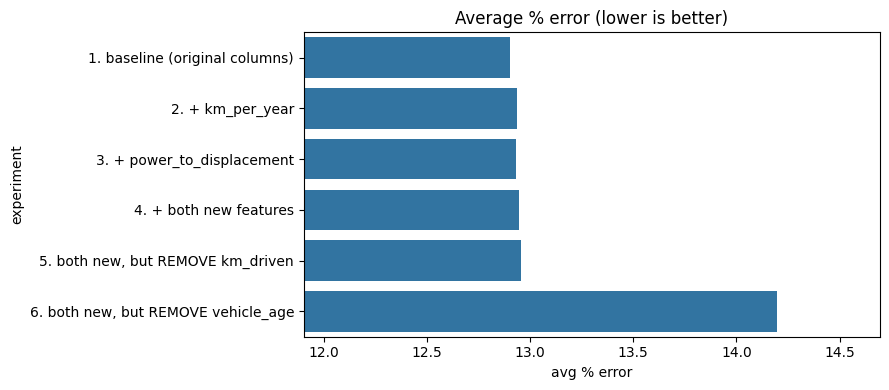

In [14]:
plt.figure(figsize=(9, 4))
sns.barplot(data=results, y="experiment", x="avg % error")
plt.xlim(results["avg % error"].min() - 1, results["avg % error"].max() + 0.5)
plt.title("Average % error (lower is better)")
plt.tight_layout()
plt.show()

In [15]:
df["log_price"] = np.log1p(df["selling_price"])
test_cols = ["vehicle_age", "km_driven", "km_per_year", "engine", "max_power", "power_to_displacement", "mileage", "seats"]
corr = df[test_cols + ["log_price"]].corr(method="spearman")["log_price"].drop("log_price")
corr.sort_values(key=abs, ascending=False).round(2).to_frame("corr with log_price")

,corr with log_price
max_power,0.72
engine,0.64
vehicle_age,-0.48
power_to_displacement,0.37
mileage,-0.28
seats,0.27
km_per_year,0.22
km_driven,-0.17


In [16]:
rows = []
for name, number_cols in experiments.items():
    pipe = make_pipeline(LinearRegression(), scale=True, number_cols=number_cols)
    s = cross_validate(pipe, X_train, y_train, cv=folds, scoring=scoring)
    rows.append({"experiment": name,
                 "R2": s["test_r2"].mean(),
                 "avg % error": -s["test_mape"].mean() * 100,
                 "std of % error": (-s["test_mape"]).std() * 100})

pd.DataFrame(rows).round(3)

,experiment,R2,avg % error,std of % error
0,1. baseline (original columns),0.805,16.265,0.356
1,2. + km_per_year,0.806,16.251,0.339
2,3. + power_to_displacement,0.802,16.274,0.348
3,4. + both new features,0.804,16.261,0.334
4,"5. both new, but REMOVE km_driven",0.804,16.255,0.334
5,"6. both new, but REMOVE vehicle_age",0.011,22.329,2.611


SUMMARY: which features to keep

What this tells us:
- `km_per_year` and `power_to_displacement` do **not** improve either model. The differences between rows 1 to 5 are far smaller than the noise. `power_to_displacement` does correlate with price (0.37), but `max_power` and `engine` already carry most of that information.
- Removing `km_driven` changes nothing, so it is redundant (it overlaps with `vehicle_age` and `km_per_year`), but it does no harm.
- Removing `vehicle_age` clearly hurts (12.9 to 14.2, and linear goes from 16 to 22). **Keep `vehicle_age`.**

Decision: the data does not show that the two new features help.